# Caso 14. Contexto de las variables aleatorias continuas

**Nombre:** Kevin Abraham Fernandez Sanchez  
**Carrera:** Ingeniería Informática  
**Institución:** Instituto Tecnológico de Durango (ITD)  
**Materia:** Probabilidad y Estadística  
**Fecha:** 5 de octubre de 2026

# Objetivo

Construir valores de variables aleatorias continuas usando `random`, y ver cómo se comportan con una tabla de distribución, un histograma y su densidad. También calcular probabilidades de intervalos.

# Fundamento teórico

Una variable continua es la que puede tomar cualquier valor real dentro de un intervalo. Por ejemplo, una persona puede medir 170 cm, 170.2 cm o 170.25 cm, y entre un valor y otro siempre hay más valores. En cambio, una variable discreta solo toma valores sueltos, casi siempre enteros, como el número de hermanos que tiene alguien.

También cambia la forma de sacar las probabilidades. En una variable discreta la función de probabilidad $f(x)$ da la probabilidad de cada valor. En una variable continua, $f(x)$ es la **función de densidad de probabilidad** y no da la probabilidad de forma directa. Lo que da la probabilidad es el **área bajo la curva** de $f(x)$ en un intervalo (Anderson et al., 2008):

$$P(a \le X \le b) = \int_a^b f(x)\,dx$$

Como el área bajo la curva en un solo punto es cero, la probabilidad de que la variable valga exactamente un número es 0, o sea $P(X = a) = 0$. Por ejemplo, es casi imposible encontrar a alguien que mida justo 162.35 cm. Por eso en las variables continuas siempre se trabaja con rangos. Si de 100 personas hay 20 que miden entre 150 y 170 cm, la probabilidad de ese rango es de 20%.

Dos cosas más de la densidad: nunca es negativa y el área total bajo la curva es 1 (o sea 100%).

### La densidad

La forma más fácil de entenderla es como el polígono de frecuencias que saldría si tuviéramos infinitos datos. En vez de picos, queda una curva suave y continua. En los histogramas de este caso es la línea que se dibuja encima de las barras.

# Desarrollo

## Librerías

Primero cargo las librerías. `pandas` es para las tablas, `numpy` para generar los datos con random, `seaborn` y `matplotlib` para los histogramas. De `scipy.stats` voy a usar las distribuciones para calcular probabilidades más exactas. `display` y `HTML` son para mostrar las tablas más bonitas.

In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
from scipy import stats  # distribuciones para calcular probabilidades

from IPython.display import display, HTML  # para mostrar tablas en html

## Crear funciones

Aquí dejo las funciones que voy a usar en los tres ejercicios, para no repetir código:

- `f_visualizar_histograma_continua`: dibuja el histograma con la curva de densidad. Recibe los datos y el número de clases `k`.
- `f_construye_tabla_distribucion_continua`: arma la tabla de distribución con frecuencia, frecuencia relativa, porcentaje y frecuencia acumulada. Calcula `n` dentro de la función para no depender de una variable de afuera.
- `f_probabilidad_empirica`: cuenta qué proporción de los datos cae entre dos valores `a` y `b`. Es la forma de sacar la probabilidad contando los datos.

In [ ]:
def f_visualizar_histograma_continua(datos, k, titulo='Distribución de Variable Continua'):
  # Histograma de la variable continua con su curva de densidad (kde)
  sns.histplot(data=datos, x=datos.columns[0], kde=True, bins=k)
  plt.xlabel(datos.columns[0])
  plt.ylabel('Frecuencia')
  plt.title(titulo)
  plt.show()

# Recibe los datos con una variable continua y el número de clases (k)
# y construye la tabla de distribución con esas k clases
def f_construye_tabla_distribucion_continua(datos, k):
  n = len(datos)

  # Crear la tabla de frecuencia agrupando en k intervalos
  tabla_frecuencia = pd.cut(datos.iloc[:, 0], bins=k, include_lowest=True).value_counts().reset_index()
  tabla_frecuencia.columns = ['Clase', 'Frec']

  # Ordenar la tabla por intervalo
  tabla_frecuencia = tabla_frecuencia.sort_values(by='Clase')
  tabla_frecuencia = tabla_frecuencia.reset_index(drop=True)  # Regenera index

  # Columnas siguientes
  tabla_frecuencia['Frec Rel'] = tabla_frecuencia['Frec'] / n
  tabla_frecuencia['Frec Porc'] = tabla_frecuencia['Frec'] / n * 100
  tabla_frecuencia['Frec Ac'] = tabla_frecuencia['Frec'].cumsum()

  return tabla_frecuencia

# Probabilidad contando datos: proporción de datos entre a y b
def f_probabilidad_empirica(datos, a, b):
  x = datos.iloc[:, 0]
  return ((x >= a) & (x <= b)).mean()

## ¿Cómo genero los datos?

Los datos no los saco de un archivo, los genero con `numpy.random`. Para que cada vez que corra el notebook salgan los mismos números uso `np.random.seed()`. Además, cada ejercicio usa una distribución distinta:

- **Calificaciones:** distribución normal, que sale como campana.
- **Pesos de paquetes:** distribución gamma, que sale sesgada a la derecha (muchos paquetes ligeros y pocos muy pesados).
- **Tiempos de entrega:** distribución uniforme, donde todos los valores del intervalo tienen la misma posibilidad.

## Ejercicio de calificaciones

### Crear los datos

Simulo 100 calificaciones de alumnos de la materia de Probabilidad y Estadística. Uso una normal con media 84 y desviación estándar 6. Con `np.clip` las calificaciones se quedan entre 50 y 100 (no puede haber una calificación mayor que 100), y con `np.round` las dejo con dos decimales.

In [ ]:
np.random.seed(14)  # semilla para que siempre salgan los mismos datos

calificaciones = np.round(np.clip(np.random.normal(84, 6, 100), 50, 100), 2)

n = len(calificaciones)
print("Número de observaciones", n)

Número de observaciones 100


### Construir tabla de distribución de los datos mediante clases

Los datos continuos se pueden describir con una tabla de distribución que los agrupa en clases o intervalos. Aquí uso 7 clases. Primero convierto el arreglo a un DataFrame y luego llamo la función que arma la tabla.

In [ ]:
k = 7  # no. de clases o cortes

# Convertir a data.frame
datos = pd.DataFrame({'calificaciones': calificaciones})

# Llamar la función y construir la tabla de distribución
resultado = f_construye_tabla_distribucion_continua(datos, k)

# Convertir el data frame a una tabla HTML y mostrarla
tabla_html = resultado.to_html(index=False, classes='table table-bordered table-striped')
display(HTML(tabla_html))

Clase,Frec,Frec Rel,Frec Porc,Frec Ac
"(69.338, 73.746]",8,0.08,8.0,8
"(73.746, 78.121]",14,0.14,14.0,22
"(78.121, 82.497]",26,0.26,26.0,48
"(82.497, 86.873]",27,0.27,27.0,75
"(86.873, 91.249]",12,0.12,12.0,87
"(91.249, 95.624]",12,0.12,12.0,99
"(95.624, 100.0]",1,0.01,1.0,100


### Visualizar histograma y su densidad

Ahora dibujo el histograma con la misma cantidad de clases. La línea encima de las barras es la densidad.

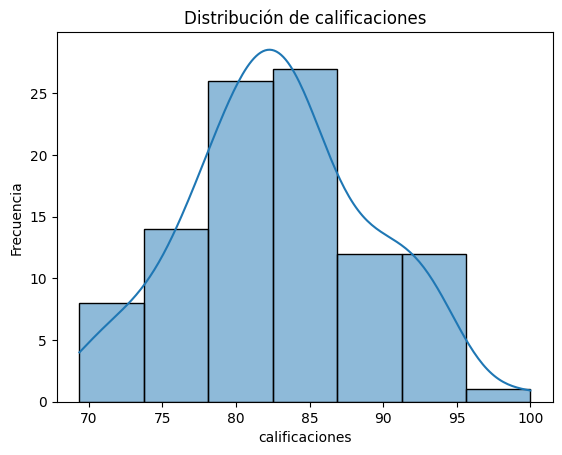

In [ ]:
f_visualizar_histograma_continua(datos, k, 'Distribución de calificaciones')

### Probabilidades

¿Cuál es la probabilidad de encontrar un alumno con un promedio exactamente igual a 80.4565? Es 0, porque es un solo punto y el área bajo la curva en un punto es cero. Por eso en variables continuas se usan intervalos.

¿Cuál es la probabilidad de encontrar un alumno con un promedio entre 80 y 85? Lo calculo de dos formas:

1. **Contando los datos:** qué proporción de los 100 alumnos quedó entre 80 y 85.
2. **Con la distribución normal:** uso la media y la desviación estándar de los datos y `stats.norm.cdf`, que da el área bajo la curva hasta un valor. La probabilidad del intervalo es el área hasta 85 menos el área hasta 80.

También saco la probabilidad de que un alumno tenga 90 o más.

In [ ]:
print("P(X = 80.4565) = 0")

a, b = 80, 85

# 1) Contando los datos
p_emp = f_probabilidad_empirica(datos, a, b)

# 2) Con la distribución normal (media y desviación de los datos)
media = datos['calificaciones'].mean()
desv = datos['calificaciones'].std()
p_teo = stats.norm.cdf(b, media, desv) - stats.norm.cdf(a, media, desv)

print(f"Media: {media:.2f}   Desviación estándar: {desv:.2f}")
print(f"P({a} <= X <= {b}) contando los datos: {p_emp:.4f} ({p_emp*100:.1f}%)")
print(f"P({a} <= X <= {b}) con la normal:      {p_teo:.4f} ({p_teo*100:.1f}%)")

# Probabilidad de 90 o más
p90_emp = (datos['calificaciones'] >= 90).mean()
p90_teo = 1 - stats.norm.cdf(90, media, desv)
print(f"P(X >= 90) contando los datos: {p90_emp:.4f} ({p90_emp*100:.1f}%)")
print(f"P(X >= 90) con la normal:      {p90_teo:.4f} ({p90_teo*100:.1f}%)")

P(X = 80.4565) = 0
Media: 82.97   Desviación estándar: 6.21
P(80 <= X <= 85) contando los datos: 0.3800 (38.0%)
P(80 <= X <= 85) con la normal:      0.3118 (31.2%)
P(X >= 90) contando los datos: 0.1500 (15.0%)
P(X >= 90) con la normal:      0.1289 (12.9%)


### Interpretación del ejercicio

Las calificaciones salieron con una media de 82.97 y una desviación estándar de 6.21. El histograma se ve como una campana: la clase que más alumnos tiene es la de 82.5 a 86.9, con 27 alumnos, y hacia los lados las barras van bajando. La densidad sigue esa misma forma.

La probabilidad de que un alumno tenga entre 80 y 85 salió de 38.0% contando los datos y de 31.2% con la normal. No son iguales pero sí se parecen. La diferencia es porque son solo 100 datos y una muestra nunca sale perfecta. Con 90 o más pasa parecido: 15.0% contando y 12.9% con la normal.

## Ejercicio de pesos de paquetes en servicio de paquetería

### Los datos

Se tiene un historial de los pesos (en kg) de paquetes que se entregan a los clientes. En una paquetería la mayoría de los paquetes pesan poco y solo unos cuantos pesan mucho, por eso uso una distribución gamma, que sale sesgada a la derecha. Le sumo 0.4 kg para que ningún paquete pese casi cero.

In [ ]:
np.random.seed(15)  # semilla para que siempre salgan los mismos datos

pesos = np.round(np.random.gamma(2.0, 2.2, 100) + 0.4, 3)

n = len(pesos)
print("Número de observaciones", n)

Número de observaciones 100


### Construir tabla de distribución de los datos mediante clases

Para los pesos uso 7 clases. Es el mismo proceso: paso los datos a un DataFrame y llamo la función.

In [ ]:
k = 7  # no. de clases o cortes

# Convertir a data.frame
datos = pd.DataFrame({'pesos': pesos})

# Llamar la función y construir la tabla de distribución
resultado = f_construye_tabla_distribucion_continua(datos, k)

# Convertir el data frame a una tabla HTML y mostrarla
tabla_html = resultado.to_html(index=False, classes='table table-bordered table-striped')
display(HTML(tabla_html))

Clase,Frec,Frec Rel,Frec Porc,Frec Ac
"(0.458, 2.456]",26,0.26,26.0,26
"(2.456, 4.439]",36,0.36,36.0,62
"(4.439, 6.422]",23,0.23,23.0,85
"(6.422, 8.404]",2,0.02,2.0,87
"(8.404, 10.387]",7,0.07,7.0,94
"(10.387, 12.37]",3,0.03,3.0,97
"(12.37, 14.353]",3,0.03,3.0,100


### Visualizar histograma y su densidad

Dibujo el histograma de los pesos. Aquí la forma ya no debería ser de campana.

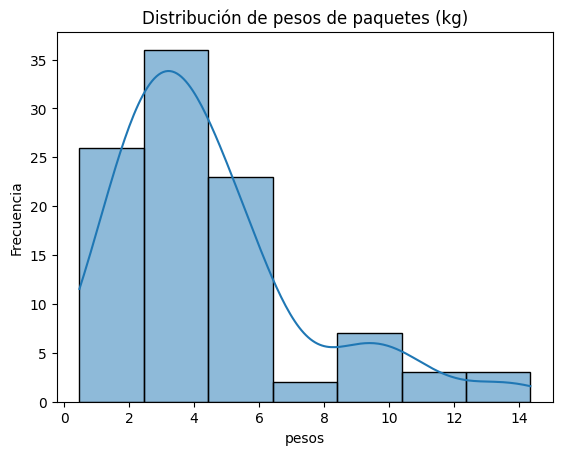

In [ ]:
f_visualizar_histograma_continua(datos, k, 'Distribución de pesos de paquetes (kg)')

### Probabilidades

¿Cuál es la probabilidad de que un paquete pese exactamente 3.5 kg? Es 0, igual que antes.

¿Cuál es la probabilidad de que un paquete pese entre 2 y 5 kg? La saco contando los datos. Para comparar, también la calculo como si los pesos fueran una normal con su media y desviación estándar, para ver si esa distribución sirve aquí. También saco la probabilidad de que pese más de 8 kg.

In [ ]:
print("P(X = 3.5) = 0")

a, b = 2, 5

# 1) Contando los datos
p_emp = f_probabilidad_empirica(datos, a, b)

# 2) Como si fuera normal (para comparar)
media = datos['pesos'].mean()
desv = datos['pesos'].std()
p_norm = stats.norm.cdf(b, media, desv) - stats.norm.cdf(a, media, desv)

print(f"Media: {media:.2f}   Mediana: {datos['pesos'].median():.2f}   Desviación estándar: {desv:.2f}")
print(f"P({a} <= X <= {b}) contando los datos: {p_emp:.4f} ({p_emp*100:.1f}%)")
print(f"P({a} <= X <= {b}) suponiendo normal:  {p_norm:.4f} ({p_norm*100:.1f}%)")

# Probabilidad de más de 8 kg
p8_emp = (datos['pesos'] > 8).mean()
p8_norm = 1 - stats.norm.cdf(8, media, desv)
print(f"P(X > 8) contando los datos: {p8_emp:.4f} ({p8_emp*100:.1f}%)")
print(f"P(X > 8) suponiendo normal:  {p8_norm:.4f} ({p8_norm*100:.1f}%)")

P(X = 3.5) = 0
Media: 4.45   Mediana: 3.64   Desviación estándar: 2.91
P(2 <= X <= 5) contando los datos: 0.5300 (53.0%)
P(2 <= X <= 5) suponiendo normal:  0.3746 (37.5%)
P(X > 8) contando los datos: 0.1400 (14.0%)
P(X > 8) suponiendo normal:  0.1115 (11.2%)


### Interpretación del ejercicio

Los pesos tienen una forma distinta a la de las calificaciones. La mayoría de los paquetes son ligeros y la clase que más datos tiene es la de 2.5 a 4.4 kg, con 36 paquetes. Después las barras bajan y queda una cola larga hacia la derecha por los pocos paquetes muy pesados. A eso se le llama sesgo a la derecha. Se nota también en que la media (4.45 kg) es mayor que la mediana (3.64 kg), porque los paquetes pesados jalan la media hacia arriba.

Por esa forma, la normal no sirve bien aquí. Entre 2 y 5 kg salió 53.0% contando los datos, pero 37.5% suponiendo normal, y es una diferencia grande. Con más de 8 kg salió 14.0% contando contra 11.2% con la normal. Para este tipo de datos hay que usar otra distribución, no la normal.

## Tiempo de llegada de un pedido de comida a domicilio

### Los datos

El tiempo que tarda en llegar un pedido a domicilio es más o menos parejo entre 15 y 30 minutos. Puede llegar en cualquier momento de ese rango y todos los tiempos tienen la misma posibilidad. Esa es una distribución uniforme, y la simulo con `np.random.uniform(15, 30, 100)`.

In [ ]:
np.random.seed(16)  # semilla para que siempre salgan los mismos datos

tiempos = np.round(np.random.uniform(15, 30, 100), 1)

n = len(tiempos)
print("Número de observaciones", n)

Número de observaciones 100


### Construir tabla de distribución

Para los tiempos uso 6 clases. Como son 15 minutos de rango, cada clase abarca como 2.5 minutos.

In [ ]:
k = 6  # no. de clases o cortes

# Convertir a data.frame
datos = pd.DataFrame({'tiempos': tiempos})

# Llamar la función y construir la tabla de distribución
resultado = f_construye_tabla_distribucion_continua(datos, k)

# Convertir el data frame a una tabla HTML y mostrarla
tabla_html = resultado.to_html(index=False, classes='table table-bordered table-striped')
display(HTML(tabla_html))

Clase,Frec,Frec Rel,Frec Porc,Frec Ac
"(15.185, 17.617]",19,0.19,19.0,19
"(17.617, 20.033]",14,0.14,14.0,33
"(20.033, 22.45]",16,0.16,16.0,49
"(22.45, 24.867]",14,0.14,14.0,63
"(24.867, 27.283]",23,0.23,23.0,86
"(27.283, 29.7]",14,0.14,14.0,100


### Visualizar histograma y su densidad

Dibujo el histograma de los tiempos. Si fuera una uniforme perfecta, todas las barras serían igual de altas.

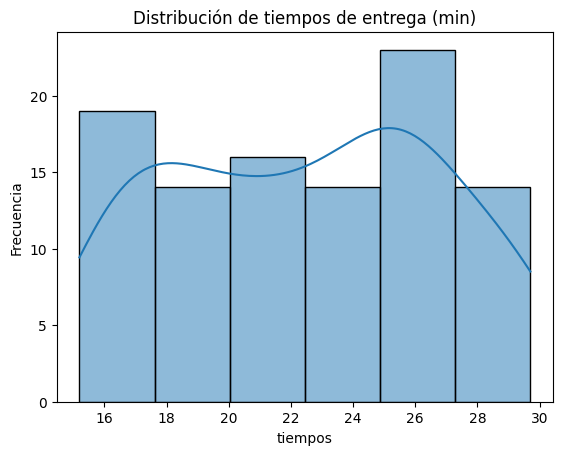

In [ ]:
f_visualizar_histograma_continua(datos, k, 'Distribución de tiempos de entrega (min)')

### Probabilidades

¿Cuál es la probabilidad de que el pedido llegue exactamente a los 20.5 minutos? Es 0.

¿Cuál es la probabilidad de que llegue entre 18 y 24 minutos? En la uniforme el área es un rectángulo, así que la probabilidad teórica es el ancho del intervalo entre el ancho total: $(24-18)/(30-15)$. Con `stats.uniform.cdf` se calcula igual, solo hay que darle el inicio (`loc=15`) y el ancho (`scale=15`) de la distribución. Lo comparo con lo que sale contando los datos. También saco la probabilidad de que tarde más de 27 minutos.

In [ ]:
print("P(X = 20.5) = 0")

a, b = 18, 24

# 1) Contando los datos
p_emp = f_probabilidad_empirica(datos, a, b)

# 2) Con la distribución uniforme entre 15 y 30
p_teo = stats.uniform.cdf(b, loc=15, scale=15) - stats.uniform.cdf(a, loc=15, scale=15)

print(f"P({a} <= X <= {b}) contando los datos: {p_emp:.4f} ({p_emp*100:.1f}%)")
print(f"P({a} <= X <= {b}) con la uniforme:    {p_teo:.4f} ({p_teo*100:.1f}%)")

# Probabilidad de más de 27 minutos
p27_emp = (datos['tiempos'] > 27).mean()
p27_teo = 1 - stats.uniform.cdf(27, loc=15, scale=15)
print(f"P(X > 27) contando los datos: {p27_emp:.4f} ({p27_emp*100:.1f}%)")
print(f"P(X > 27) con la uniforme:    {p27_teo:.4f} ({p27_teo*100:.1f}%)")

P(X = 20.5) = 0
P(18 <= X <= 24) contando los datos: 0.4000 (40.0%)
P(18 <= X <= 24) con la uniforme:    0.4000 (40.0%)
P(X > 27) contando los datos: 0.1600 (16.0%)
P(X > 27) con la uniforme:    0.2000 (20.0%)


### Interpretación del ejercicio

Los tiempos van de 15.2 a 29.7 minutos y todas las clases tienen datos. Las barras no quedaron exactamente iguales (van de 14 a 23 datos por clase), pero no hay una clase que domine como pasaba con las calificaciones o los pesos. Es lo normal en una uniforme con datos simulados, porque el azar nunca da una forma perfecta.

Entre 18 y 24 minutos la probabilidad teórica es 40.0% y contando los datos salió 40.0%. Para más de 27 minutos la teórica es 20.0% y contando salió 16.0%. En este caso la uniforme sí describe bien los datos.

# Interpretación del caso

En este caso generé datos de tres variables aleatorias continuas con random: calificaciones, pesos de paquetes y tiempos de entrega. Para cada una hice la tabla de distribución, el histograma con su densidad y calculé probabilidades de intervalos.

Las clases de la tabla agrupan valores dentro de un intervalo, y el histograma deja ver la forma de los datos. Las tres formas fueron distintas: las calificaciones salieron en forma de campana, los pesos sesgados a la derecha y los tiempos más o menos parejos. La curva de la densidad es la que representa esa forma pensando en infinitos valores.

También quedó claro que la probabilidad de un valor exacto es 0 y que solo tiene sentido hablar de probabilidad en intervalos. Contando los datos se puede sacar una probabilidad aproximada, pero cambia si cambia la muestra. En las calificaciones el intervalo de 80 a 85 dio 38.0% contando y 31.2% con la normal, y en los pesos la normal ni siquiera sirvió porque la forma de los datos no es de campana.

¿Cómo obtener probabilidades de forma más exacta? Con la función de densidad: la probabilidad es el área bajo la curva en el intervalo, que se puede calcular con integrales o con funciones de Python como `cdf` de `scipy.stats`. Lo importante es escoger la distribución que se parezca a los datos, porque si no, como pasó con los pesos, el resultado sale mal.